<a href="https://colab.research.google.com/github/EmilKarimov3/Emil_INFO4670_Fall2026/blob/main/Logistic_Regression_Car_Assignment_Emil.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

df = pd.read_csv("car_purchase_data.csv")
display(df.head())

,User ID,Gender,Age,Salary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


### Step 2: Split features and target

In [9]:
X = df[["Age", "Salary"]]
y = df["Purchased"]

display(X.head())
display(y.head())

,Age,Salary
0,19,19000
1,35,20000
2,26,43000
3,27,57000
4,19,76000


,Purchased
0,0
1,0
2,0
3,0
4,0


### Step 3: Train/Test Split

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=0
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 320
Testing rows: 80


### Step 4: Feature Scaling

In [11]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("First 5 scaled training rows:")
print(X_train_scaled[:5])

First 5 scaled training rows:
[[ 1.92295008  2.14601566]
 [ 2.02016082  0.3787193 ]
 [-1.3822153  -0.4324987 ]
 [-1.18779381 -1.01194013]
 [ 1.92295008 -0.92502392]]


### Step 5: Train Logistic Regression Model

In [12]:
model = LogisticRegression(random_state=0, max_iter=1000)
model.fit(X_train_scaled, y_train)

print("Model training complete.")

Model training complete.


### Step 6: Predict and Evaluate

In [13]:
y_pred = model.predict(X_test_scaled)

accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: {accuracy * 100:.2f}%")

print("\nConfusion matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification report:")
print(classification_report(y_test, y_pred))

Test accuracy: 92.50%

Confusion matrix:
[[57  1]
 [ 5 17]]

Classification report:
              precision    recall  f1-score   support

           0       0.92      0.98      0.95        58
           1       0.94      0.77      0.85        22

    accuracy                           0.93        80
   macro avg       0.93      0.88      0.90        80
weighted avg       0.93      0.93      0.92        80



### Step 7: Visualization of Decision Regions

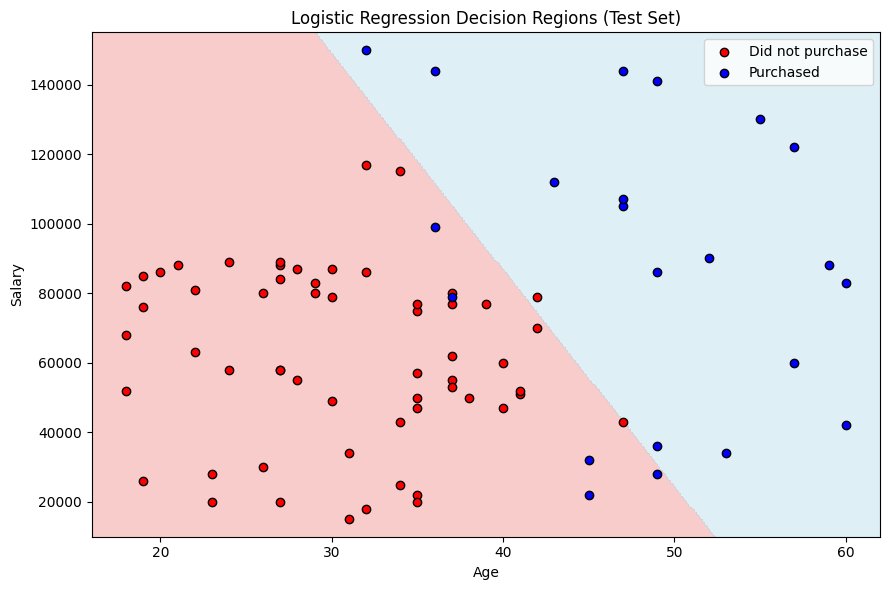

In [14]:
from matplotlib.colors import ListedColormap

# Create a grid of age and salary values
age_grid, salary_grid = np.meshgrid(
    np.linspace(X["Age"].min() - 2, X["Age"].max() + 2, 300),
    np.linspace(X["Salary"].min() - 5000,
                X["Salary"].max() + 5000, 300)
)

grid = pd.DataFrame({
    "Age": age_grid.ravel(),
    "Salary": salary_grid.ravel()
})

# Predict the class at each grid point
grid_predictions = model.predict(scaler.transform(grid))
grid_predictions = grid_predictions.reshape(age_grid.shape)

# Background colors show predicted classes
plt.figure(figsize=(9, 6))
plt.contourf(
    age_grid, salary_grid, grid_predictions,
    levels=[-0.5, 0.5, 1.5],
    cmap=ListedColormap(["lightcoral", "lightblue"]),
    alpha=0.4
)

# Dots show actual test outcomes
for outcome, color, label in [
    (0, "red", "Did not purchase"),
    (1, "blue", "Purchased")
]:
    plt.scatter(
        X_test.loc[y_test == outcome, "Age"],
        X_test.loc[y_test == outcome, "Salary"],
        c=color, label=label, edgecolors="black"
    )

plt.xlabel("Age")
plt.ylabel("Salary")
plt.title("Logistic Regression Decision Regions (Test Set)")
plt.legend()
plt.tight_layout()
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

Objective

We want to predict if a customer will buy a car based on their age and salary. A logistic regression model will create a linear combination of the features with weights to pass into a sigmoid function to get a value from 0 to 1 (a probability). This is a good choice for this objective because there are only two values associated with the target variable Purchased (0 = no purchase and 1 = purchase).

1. How is logistic regression used for classification?

A threshold value (typically 0.5) is used to convert a probability into a class. If the probability is greater than 0.5 then a purchase is predicted and if it is less than 0.5 no purchase is predicted. This allows a probability to be turned into a yes/no decision.

2. How do we know which customers are more likely to buy a car?

Based on this model the higher the age or the higher the salary holding the other attribute constant, the higher the predicted probability of purchase. From the plot it appears older customers can be predicted to purchase at a lower salary and younger customers are more likely to only purchase at a higher salary. This is only based on trends in this dataset and not necessarily for every customer.

3. What could cause poor performance?

Not all purchase decisions can be explained by age and salary. Two customers with the same age and same salary could make different purchase decisions. Errors or missing data as well as trends that cannot be separated by a linear decision boundary could also cause poor performance. In my model, I achieved 92.5% accuracy on the test data with correct predictions for 74 out of 80 customers. 5 actual purchases were incorrectly predicted as not purchases and 1 not a purchase was incorrectly predicted as a purchase. The model was good at predicting non purchases.

4. How can performance be improved?

Potential additional attributes that could be useful include a previous purchase history, current ownership of a car, and the price of the desired vehicle. Care can also be taken to ensure there are no data entry errors or missing data. Also, adding interaction effects between age and salary or using age and salary squared could potentially be useful to better model the relationships. All improvements should be tested with cross validation on the training data while keeping the test data intact for final testing.